# MM HW 07

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

data_A = np.loadtxt("lifetimes_A.txt")
data_B = np.loadtxt("lifetimes_B-1.txt")

## Part i

In [12]:
bins = np.array([0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, np.inf]) # the "linspace" 
Oa, _ = np.histogram(data_A, bins=bins) # creates histogram begind the scene instead of using plt.hist returns bin edge var we don't care about per documentation
Ob, _ =  np.histogram(data_B, bins=bins)

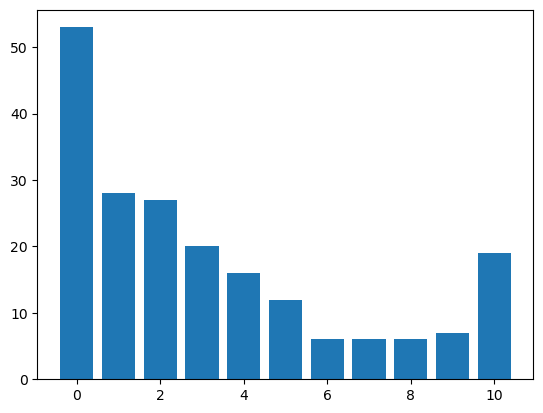

In [13]:
plt.bar(range(len(Oa)), Oa)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

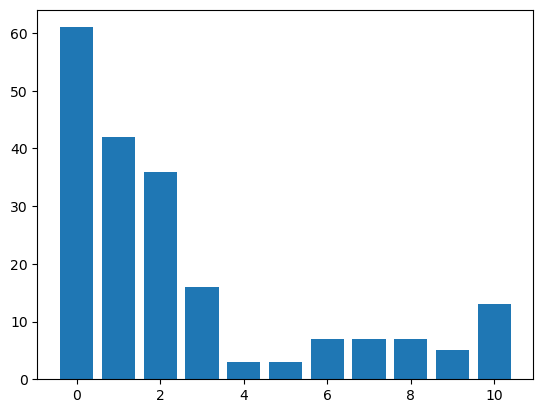

In [15]:
plt.bar(range(len(Ob)), Ob)
plt.show

## Part ii

In [30]:
Ea = 200 * (np.exp(-bins[:-1] / 100) - np.exp(-bins[1:] / 100)) 
# solved analytically on paper (also turned in) which is where I am getting the (e^{step initial} - e^{step final}) * 200 equation I am automating

T = 0 # sum starts at 0

for i in range(len(Oa)):
    T += (Oa[i] - Ea[i])**2 / Ea[i] # add piece to T

freedom = 11-1 # number of bins - 1 would be the degrees of freedom since we're constraining the bins
p_A = chi2.sf(T, freedom)

print("T:", T)
print("DoF:", freedom)
print("Pa:", p_A)

T: 6.490390467284771
DoF: 10
Pa: 0.7725189942648265


In [35]:
Eb = 200 * (np.exp(-bins[:-1] / 100) - np.exp(-bins[1:] / 100)) 
# solved analytically on paper (also turned in) which is where I am getting the (e^{step initial} - e^{step final}) * 200

T = 0 # sum starts at 0

for i in range(len(Ob)):
    T += (Ob[i] - Eb[i])**2 / Eb[i] # add piece to T

freedom = 11-1 # number of bins - 1 would be the degrees of freedom since we're constraining the bins
p_B = chi2.sf(T, freedom)

print("T:", T)
print("DoF:", freedom)
print("Pb:", p_B)

T: 32.2983538375235
DoF: 10
Pb: 0.00035707002905453056


## Part iii

In [42]:
# tau is mean of data
taua = np.mean(data_A)
taub = np.mean(data_B)

print("tau a:", taua)
print("tau b:", taub)


tauEa = 200 * (np.exp(-bins[:-1] / taua) - np.exp(-bins[1:] / taua)) 
tauEb = 200 * (np.exp(-bins[:-1] / taub) - np.exp(-bins[1:] / taub)) 


def soup(in_put, stuff):
    T = 0
    for i in range(len(in_put)):
        T += (in_put[i] - stuff[i])**2 / stuff[i] # add piece to T
    return T


tauTa = soup(Oa, tauEa)
tauTb = soup(Ob, tauEb)

freedom = 11-1-1 # for he hath giveth the mean, he then taketh another dof
taup_a = chi2.sf(tauTa, freedom)
taup_b = chi2.sf(tauTb, freedom)

print("\n\nDoF:", freedom)
print(f"Ta: {tauTa}, Tb: {tauTb}")
print(f"Pa: {taup_a}, Pb: {taup_b}")

tau a: 99.88656499500001
tau b: 83.25430232999999


DoF: 9
Ta: 6.496871734346591, Tb: 24.78173289796044
Pa: 0.689341675709589, Pb: 0.0032223532785285993


### Explain why estimating a parameter from the same data changes the number of degrees of freedom:

We are using the data to generate the mean, which is equal to tau which is what we are trying to estimate. We are then using this estimator generated from the data to perform a goodness of fit test for the data. Since this is being taken from our sample data aka another restriction on the data, this then reduces our degrees of freedom again. It would be silly if we could generate infinite numbers of estimators/parameters and perfectly fit the data without taking a hit somewhere. 